# 01 Who moves together: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded, computed, printed or plotted here.** Part B (test years) comes later, after the predictions are written.

Plain-language key
- **Daily return** = percent change in adjusted close (dividends included) from one trading day to the next.
- **Correlation** = how closely two daily-return series move together, from -1 (always opposite) to +1 (always together). Computed on returns, never prices.
- **Plain view** = correlation of the daily returns as they are.
- **Market-removed view** = first strip out the part of each symbol's move explained by the overall market, then correlate what is left over. *Market* = equal-weight average of whichever of the 11 sector funds exist on each date. For each symbol and each calendar year, regress its daily return on the market's daily return; the leftover (residual) is what the market did not explain. Note: SPY's leftover means "S&P 500 vs the equal-weight sector average", i.e. a big-company tilt. A sector fund is also part of the average it is compared with, which slightly pulls its leftover away from the other sectors.
- Rules: each pair uses only days both have data; a pair needs 252+ shared days for the whole-period number and 120+ shared days for a year.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import config
from rotation.data import load_prices, wide
from rotation.returns import daily_returns
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)

MIN_WHOLE, MIN_YEAR, ROLL = 252, 120, 63
ORDER = config.SECTORS + config.INDUSTRIES + ["SPY", "QQQ", "IWM", "GLD", "TLT", "USO", "UUP", "EEM", "BTC-USD"]
assert sorted(ORDER) == sorted(config.ALL_SYMBOLS)

## 1. Load build years only
The filter is applied while reading the file, before any calculation.

In [2]:
df = load_prices(fields=["adj_close"], end=config.BUILD_END)
adj = wide(df, "adj_close")[ORDER]
assert adj.index.max() <= pd.Timestamp(config.BUILD_END)
print("rows:", len(adj), "| first", adj.index.min().date(), "| last", adj.index.max().date())
ret = daily_returns(adj).iloc[1:]
sectors_ret = ret[config.SECTORS]
market = sectors_ret.mean(axis=1, skipna=True)          # equal weight of sectors that exist that day
print("sectors available: min", sectors_ret.notna().sum(axis=1).min(), "max", sectors_ret.notna().sum(axis=1).max())

rows: 5536 | first 1999-01-04 | last 2020-12-31
sectors available: min 9 max 11


## 2. Market-removed returns (leftovers)
Per symbol and calendar year: `r = a + b * market + leftover`. A symbol-year needs 120+ days.

In [3]:
res = pd.DataFrame(np.nan, index=ret.index, columns=ret.columns)
for s in ret.columns:
    for y, g in ret[s].groupby(ret.index.year):
        d = pd.concat([g, market.loc[g.index]], axis=1, keys=["r", "m"]).dropna()
        if len(d) < MIN_YEAR:
            continue
        b, a = np.polyfit(d["m"], d["r"], 1)
        res.loc[d.index, s] = d["r"] - (a + b * d["m"])
print("leftover days per symbol:"); print(res.notna().sum().to_string())

leftover days per symbol:
symbol
XLK        5535
XLE        5535
XLV        5535
XLU        5535
XLF        5535
XLI        5535
XLB        5535
XLP        5535
XLY        5535
XLC         639
XLRE       1259
SMH        5177
XBI        3752
KRE        3657
ITA        3690
SPY        5535
QQQ        5490
IWM        5182
GLD        4028
TLT        4532
USO        3708
UUP        3485
EEM        4461
BTC-USD    1511


## 3. Correlations: whole period and year by year

In [4]:
PAIRS = list(itertools.combinations(ORDER, 2))   # canonical order = display order
views = {"plain": ret, "market-removed": res}

def counts(frame):
    n = frame.notna().astype(int)
    return n.T @ n

whole = []
cw = {v: f.corr(min_periods=MIN_WHOLE) for v, f in views.items()}
nw = {v: counts(f) for v, f in views.items()}
for a, b in PAIRS:
    if nw["plain"].loc[a, b] < MIN_WHOLE:
        continue
    whole.append(dict(symbol_a=a, symbol_b=b, days_plain=int(nw["plain"].loc[a, b]),
                      plain_corr=cw["plain"].loc[a, b],
                      days_removed=int(nw["market-removed"].loc[a, b]),
                      removed_corr=cw["market-removed"].loc[a, b]))
whole = pd.DataFrame(whole)
whole.to_csv(R / "01_correlations_whole_period.csv", index=False)

yr = []
for v, f in views.items():
    for y, g in f.groupby(f.index.year):
        c = g.corr(min_periods=MIN_YEAR); n = counts(g)
        for a, b in PAIRS:
            if n.loc[a, b] >= MIN_YEAR and pd.notna(c.loc[a, b]):
                yr.append(dict(year=y, pair=f"{a}-{b}", view=v, correlation=c.loc[a, b], days=int(n.loc[a, b])))
yearly = pd.DataFrame(yr)
yearly.to_csv(R / "01_correlations_by_year.csv", index=False)
print(len(whole), "pairs in whole-period table;", len(yearly), "pair-year-view rows;", "years", yearly.year.min(), "-", yearly.year.max())
whole.head()

276 pairs in whole-period table; 8108 pair-year-view rows; years 1999 - 2020


,symbol_a,symbol_b,days_plain,plain_corr,days_removed,removed_corr
0,XLK,XLE,5535,0.484613,5535,-0.290892
1,XLK,XLV,5535,0.676686,5535,0.037556
2,XLK,XLU,5535,0.463665,5535,-0.213121
3,XLK,XLF,5535,0.637299,5535,-0.107254
4,XLK,XLI,5535,0.734386,5535,-0.027734


## 4. Steadiness per pair
Label: **steady together** = positive in at least 80% of years; **steady opposite** = negative in at least 80% of years; otherwise **flips**.

In [5]:
rows = []
for (pair, v), g in yearly.groupby(["pair", "view"]):
    c = g.correlation
    pos, neg = (c > 0).mean(), (c < 0).mean()
    label = "steady together" if pos >= 0.8 else ("steady opposite" if neg >= 0.8 else "flips")
    rows.append(dict(pair=pair, view=v, years=len(c), share_positive=pos, share_negative=neg, median_yearly=c.median(),
                     lowest=c.min(), lowest_year=int(g.loc[c.idxmin(), "year"]),
                     highest=c.max(), highest_year=int(g.loc[c.idxmax(), "year"]), label=label))
steady = pd.DataFrame(rows)
steady.to_csv(R / "01_steadiness.csv", index=False)
print(steady.groupby(["view", "label"]).size().unstack(fill_value=0))
steady.head()

label           flips  steady opposite  steady together
view                                                   
market-removed    113               94               69
plain              57               23              196


,pair,view,years,share_positive,share_negative,median_yearly,lowest,lowest_year,highest,highest_year,label
0,EEM-BTC-USD,market-removed,6,0.333333,0.666667,-0.018881,-0.112148,2017,0.166633,2018,flips
1,EEM-BTC-USD,plain,6,0.500000,0.500000,-0.004290,-0.113624,2019,0.406778,2020,flips
2,GLD-BTC-USD,market-removed,6,0.500000,0.500000,0.034341,-0.044341,2018,0.254953,2020,flips
3,GLD-BTC-USD,plain,6,0.500000,0.500000,0.038786,-0.045039,2018,0.289516,2020,flips
4,GLD-EEM,market-removed,16,1.000000,0.000000,0.205307,0.036334,2014,0.388027,2018,steady together


## 5. Normal wobble
63-day rolling correlation for every pair; per pair, the standard deviation of that rolling correlation (how much it normally drifts). Headline = median across pairs, plain view; market-removed shown too.

In [6]:
wob = []
for a, b in zip(whole.symbol_a, whole.symbol_b):
    row = dict(pair=f"{a}-{b}")
    for v, f in views.items():
        rc = f[a].rolling(ROLL, min_periods=ROLL).corr(f[b]).dropna()
        row[f"std_{v}"] = rc.std() if len(rc) > 1 else np.nan
        row[f"windows_{v}"] = len(rc)
    wob.append(row)
wob = pd.DataFrame(wob)
wob.to_csv(R / "01_rolling_wobble.csv", index=False)
print("Median wobble (std of 63-day rolling correlation) across", len(wob), "pairs:")
print("  plain view:          ", round(wob["std_plain"].median(), 3))
print("  market-removed view: ", round(wob["std_market-removed"].median(), 3))
wob.describe().loc[["min", "50%", "max"], ["std_plain", "std_market-removed"]]

Median wobble (std of 63-day rolling correlation) across 276 pairs:
  plain view:           0.204
  market-removed view:  0.173


,std_plain,std_market-removed
min,0.035333,0.101386
50%,0.203938,0.172963
max,0.345469,0.275215


## 6. Heatmaps (whole build period)
Order: 11 sectors, then SMH XBI KRE ITA, then SPY QQQ IWM GLD TLT USO UUP EEM BTC-USD. Blank = fewer than 252 shared days.

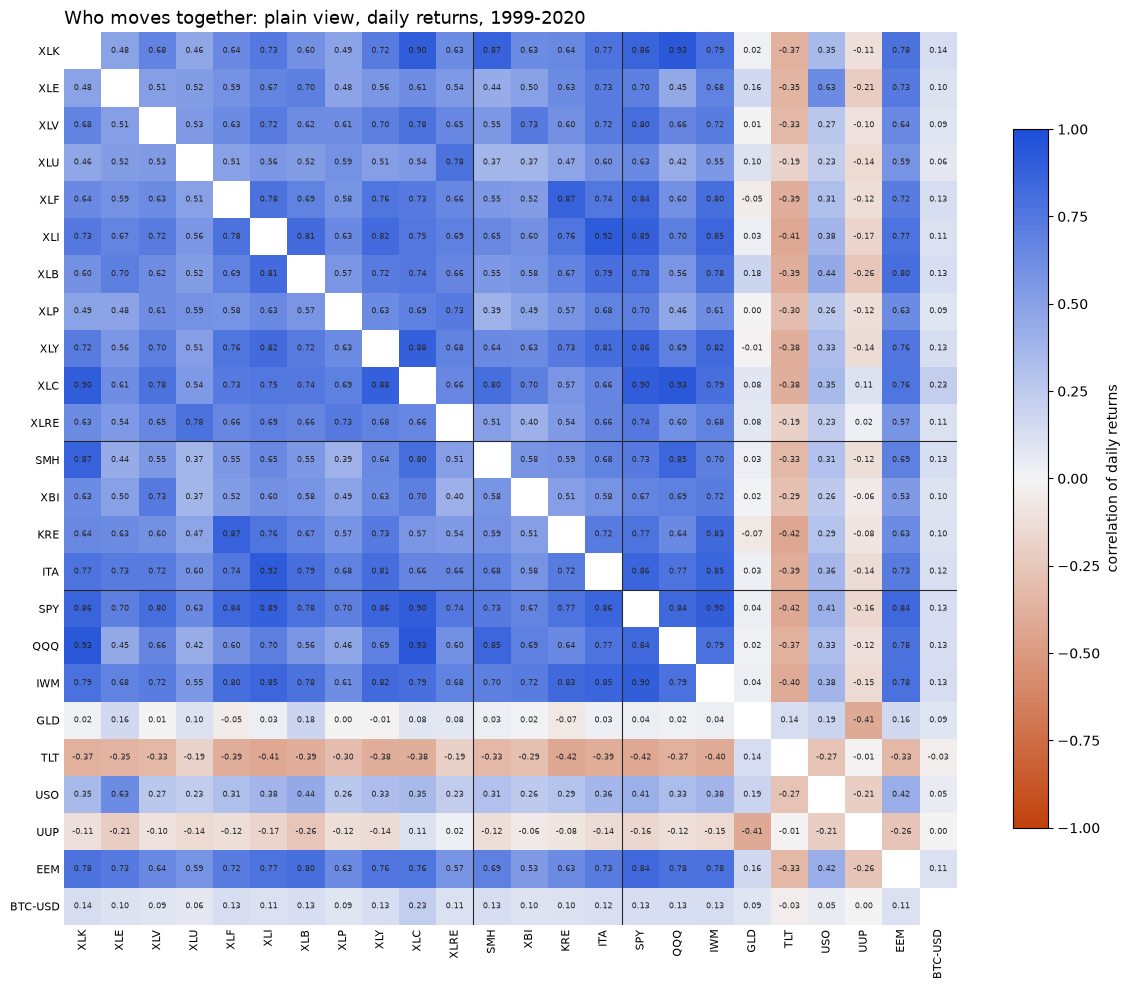

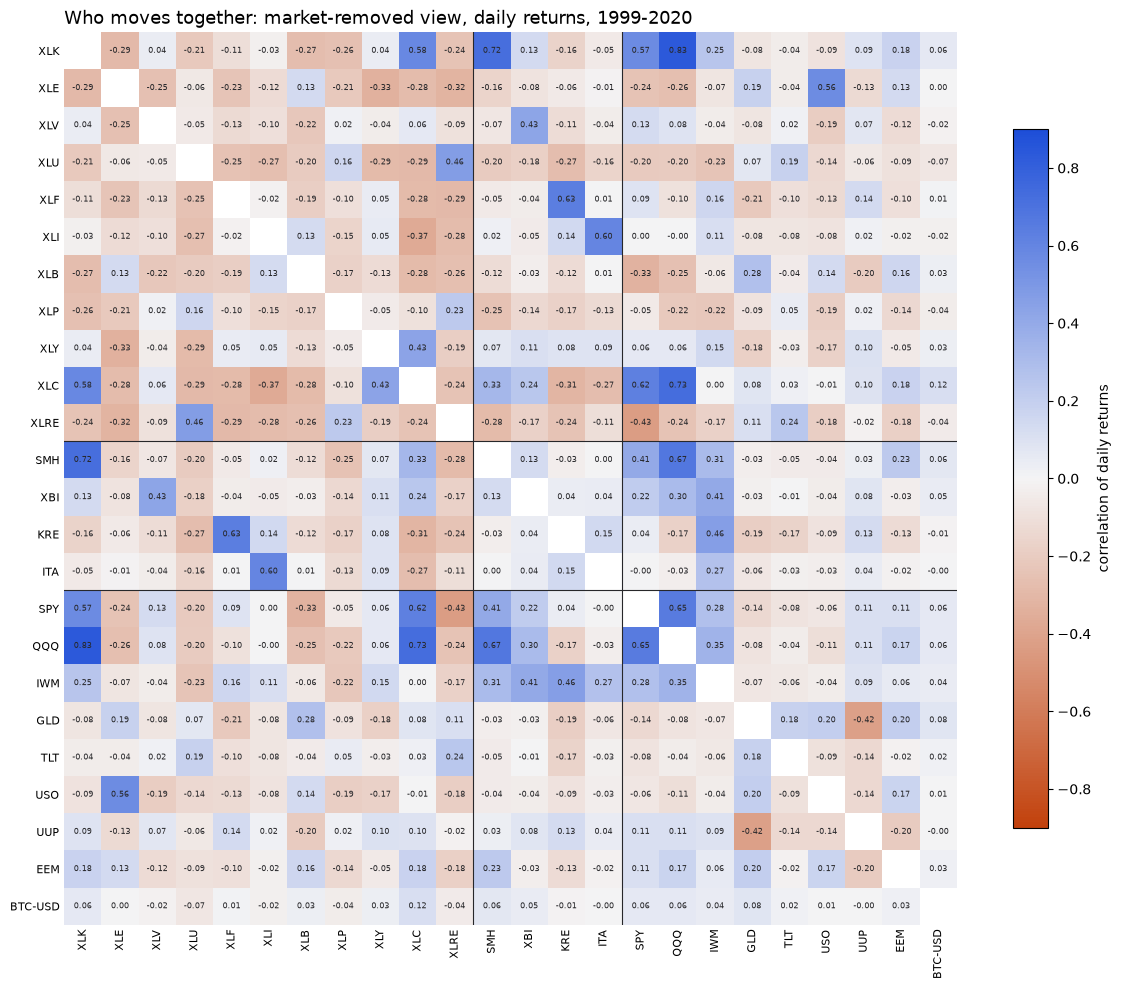

In [7]:
cmap = LinearSegmentedColormap.from_list("div", ["#c2410c", "#f4f4f5", "#1d4ed8"])
def heat(mat, title, fname, lim):
    fig, ax = plt.subplots(figsize=(12, 10.5))
    im = ax.imshow(mat.values, cmap=cmap, vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=90, fontsize=8)
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER, fontsize=8)
    for i in range(len(ORDER)):
        for j in range(len(ORDER)):
            v = mat.values[i, j]
            if pd.notna(v) and i != j:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5, color="#27272a")
    for k in (10.5, 14.5):
        ax.axhline(k, color="#27272a", lw=0.8); ax.axvline(k, color="#27272a", lw=0.8)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title, loc="left", fontsize=13)
    cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("correlation of daily returns")
    fig.tight_layout(); fig.savefig(R / fname, dpi=150); plt.show()

def full_matrix(col):
    m = pd.DataFrame(np.nan, index=ORDER, columns=ORDER)
    for _, r in whole.iterrows():
        m.loc[r.symbol_a, r.symbol_b] = m.loc[r.symbol_b, r.symbol_a] = r[col]
    return m
mp, mr = full_matrix("plain_corr"), full_matrix("removed_corr")
heat(mp, "Who moves together: plain view, daily returns, 1999-2020", "01_heatmap_plain.png", 1.0)
lim = float(np.ceil(np.nanmax(np.abs(mr.values)) * 10) / 10)
heat(mr, "Who moves together: market-removed view, daily returns, 1999-2020", "01_heatmap_market_removed.png", lim)

## 7. Most together / most opposite (market-removed view)

In [8]:
lab = steady[steady.view == "market-removed"].set_index("pair")[["years", "share_positive", "label"]]
w = whole.copy(); w["pair"] = w.symbol_a + "-" + w.symbol_b
w = w.dropna(subset=["removed_corr"]).join(lab, on="pair")
cols = ["pair", "removed_corr", "plain_corr", "days_removed", "years", "share_positive", "label"]
top_t = w.sort_values("removed_corr", ascending=False).head(10)[cols].assign(rank_type="most together")
top_o = w.sort_values("removed_corr").head(10)[cols].assign(rank_type="most opposite")
top = pd.concat([top_t, top_o]); top.to_csv(R / "01_top10_market_removed.csv", index=False)
print("TOP 10 MOST TOGETHER"); print(top_t.drop(columns="rank_type").round(3).to_string(index=False))
print("\nTOP 10 MOST OPPOSITE"); print(top_o.drop(columns="rank_type").round(3).to_string(index=False))

TOP 10 MOST TOGETHER
   pair  removed_corr  plain_corr  days_removed  years  share_positive           label
XLK-QQQ         0.831       0.934          5490     22             1.0 steady together
XLC-QQQ         0.727       0.933           639      3             1.0 steady together
XLK-SMH         0.722       0.871          5177     21             1.0 steady together
SMH-QQQ         0.673       0.851          5177     21             1.0 steady together
SPY-QQQ         0.649       0.837          5490     22             1.0 steady together
XLF-KRE         0.635       0.873          3657     15             1.0 steady together
XLC-SPY         0.624       0.903           639      3             1.0 steady together
XLI-ITA         0.596       0.919          3690     15             1.0 steady together
XLK-XLC         0.580       0.903           639      3             1.0 steady together
XLK-SPY         0.566       0.860          5535     22             1.0 steady together

TOP 10 MOST OPPOSITE


## 8. Year by year for chosen pairs (both views)

In [9]:
chosen = ["UUP-GLD", "USO-XLY", "UUP-EEM", "USO-TLT", "XLK-XLP", "SPY-TLT", "XLK-XLU", "SMH-EEM"]
canon = lambda p: "-".join(sorted(p.split("-"), key=ORDER.index))
tabs = {}
for p in chosen:
    for v in ("plain", "market-removed"):
        tabs[(p, v)] = yearly[(yearly.pair == canon(p)) & (yearly.view == v)].set_index("year").correlation
sel = pd.DataFrame(tabs); sel.columns = [f"{p} | {v}" for p, v in sel.columns]
sel.index.name = "year"
sel.to_csv(R / "01_selected_pairs_by_year.csv")
sel.round(2)

,UUP-GLD | plain,UUP-GLD | market-removed,USO-XLY | plain,USO-XLY | market-removed,UUP-EEM | plain,UUP-EEM | market-removed,USO-TLT | plain,USO-TLT | market-removed,XLK-XLP | plain,XLK-XLP | market-removed,SPY-TLT | plain,SPY-TLT | market-removed,XLK-XLU | plain,XLK-XLU | market-removed,SMH-EEM | plain,SMH-EEM | market-removed
year,,,,,,,,,,,,,,,,
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.44,-0.06,NaN,NaN,0.31,-0.23,NaN,NaN
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.13,-0.53,NaN,NaN,0.06,-0.28,NaN,NaN
2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.05,-0.45,NaN,NaN,0.12,-0.27,NaN,NaN
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.45,-0.39,NaN,NaN,0.54,-0.16,NaN,NaN
2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65,-0.14,-0.32,0.00,0.55,-0.26,0.64,0.38
2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.47,-0.16,-0.04,-0.10,0.29,-0.37,0.52,0.25
2005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.66,0.09,0.01,0.17,0.49,-0.24,0.51,0.11
2006,NaN,NaN,-0.18,-0.50,NaN,NaN,0.01,0.00,0.61,0.11,0.05,-0.11,0.37,-0.30,0.64,0.18
2007,-0.34,-0.38,0.00,-0.30,-0.01,-0.10,-0.07,-0.01,0.69,-0.05,-0.39,-0.05,0.59,-0.22,0.66,0.10


## 9. Checks for the four Part A predictions
Computed straight from the yearly table (years with 120+ shared days only).

In [10]:
def series(pair, view):
    return yearly[(yearly.pair == canon(pair)) & (yearly.view == view)].set_index("year")
out = {}
s = series("UUP-GLD", "plain").correlation
out["P1 UUP-GLD plain: share of years negative (need >= 0.80)"] = (len(s), (s < 0).mean())
print("P1 yearly:"); print(s.round(2).to_string())
tech = ["XLK", "SMH", "QQQ", "SPY"]
mins = []
for a, b in itertools.combinations(tech, 2):
    t = series(f"{a}-{b}", "plain").correlation
    mins.append((canon(f"{a}-{b}"), t.min(), int(t.idxmin()), len(t)))
print("\nP2 per tech pair: lowest yearly correlation (need every pair-year > 0.70)")
print(pd.DataFrame(mins, columns=["pair", "lowest", "year_of_lowest", "years"]).round(3).to_string(index=False))
fails = [(canon(f"{a}-{b}"), int(y), round(c, 3)) for a, b in itertools.combinations(tech, 2)
         for y, c in series(f"{a}-{b}", "plain").correlation.items() if c <= 0.70]
print("P2 pair-years at or below 0.70:", len(fails)); print(fails)
s3 = series("SPY-TLT", "plain").correlation
out["P3 SPY-TLT plain: share of years negative (need >= 0.70)"] = (len(s3), (s3 < 0).mean())
print("\nP3 yearly:"); print(s3.round(2).to_string())
s4 = series("XLK-XLP", "market-removed").correlation
out["P4 XLK-XLP market-removed: share of years negative (need >= 0.80)"] = (len(s4), (s4 < 0).mean())
print("\nP4 yearly:"); print(s4.round(2).to_string())
print()
for k, (n, v) in out.items():
    print(f"{k}: {v:.0%} of {n} years")

P1 yearly:
year
2007   -0.34
2008   -0.60
2009   -0.35
2010   -0.23
2011   -0.19
2012   -0.52
2013   -0.42
2014   -0.45
2015   -0.36
2016   -0.37
2017   -0.56
2018   -0.65
2019   -0.51
2020   -0.35

P2 per tech pair: lowest yearly correlation (need every pair-year > 0.70)
   pair  lowest  year_of_lowest  years
XLK-SMH   0.737            2007     21
XLK-QQQ   0.873            2000     22
XLK-SPY   0.781            2000     22
SMH-QQQ   0.736            2007     21
SMH-SPY   0.604            2004     21
SPY-QQQ   0.790            1999     22
P2 pair-years at or below 0.70: 4
[('SMH-SPY', 2000, 0.699), ('SMH-SPY', 2004, 0.604), ('SMH-SPY', 2005, 0.612), ('SMH-SPY', 2017, 0.652)]

P3 yearly:
year
2003   -0.32
2004   -0.04
2005    0.01
2006    0.05
2007   -0.39
2008   -0.48
2009   -0.32
2010   -0.55
2011   -0.71
2012   -0.65
2013   -0.21
2014   -0.46
2015   -0.37
2016   -0.37
2017   -0.33
2018   -0.28
2019   -0.46
2020   -0.48

P4 yearly:
year
1999   -0.06
2000   -0.53
2001   -0.45
2002   -